✅ Simulation 04 completed successfully!
📁 High-resolution figure saved at: figures/sim04_phase_space_wigner_husimi.png


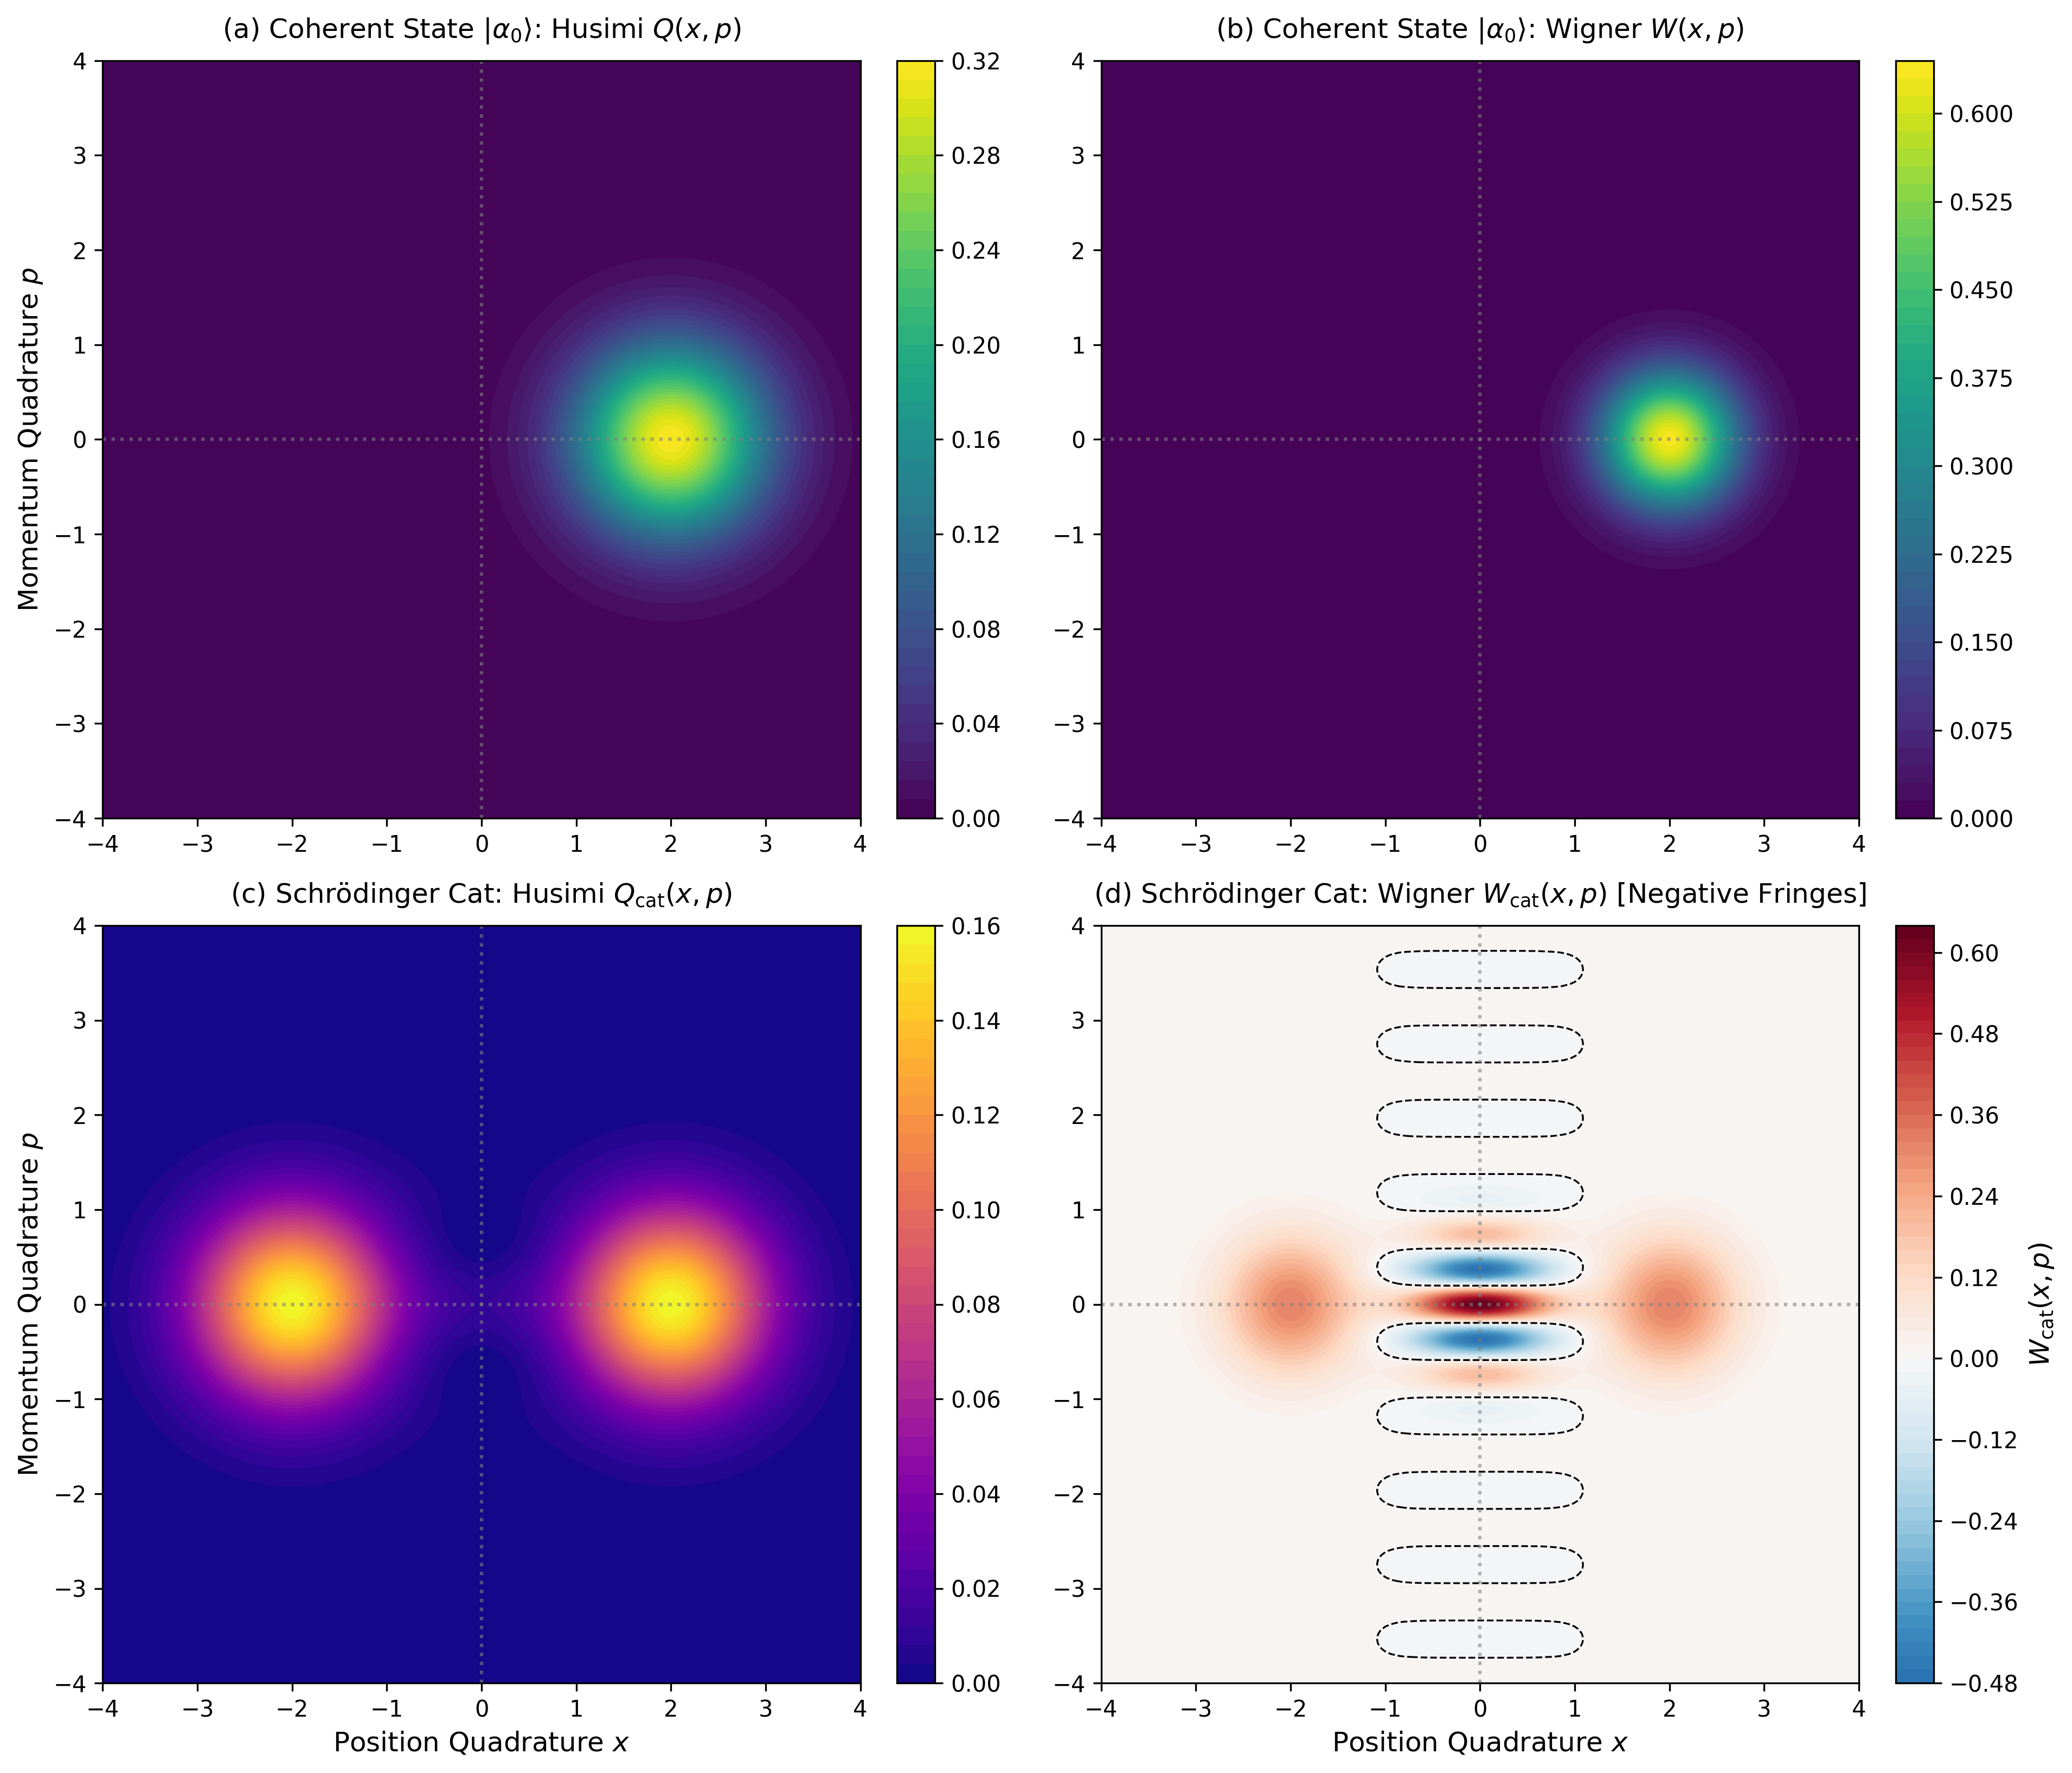

In [8]:
"""
===============================================================================
Computational Quantum Optics: Gerry & Knight Simulations
Chapter 03: Coherent States of Light
Simulation 04: Phase-Space Distributions: Husimi-Q, Wigner-W & Schrödinger Cat
===============================================================================

Reference:
    "Introductory Quantum Optics", Christopher C. Gerry & Sir Peter L. Knight,
    Chapter 3, Section 3.6: Phase-space pictures of coherent states
    & Section 3.7: Density operators and phase-space probability distributions.

Description:
    Simulates quasi-probability distributions in optical phase space (x, p).
    Contrasts the non-negative Husimi Q-function with the Wigner W-function for:
    1. A single coherent state |alpha_0> (Gaussian, minimum uncertainty).
    2. A macroscopic superposition (Schrödinger Cat State: |alpha_0> + |-alpha_0>),
       revealing quantum interference fringes with negative Wigner quasi-probabilities
       (W < 0), the definitive signature of quantum non-classicality.
"""

import os
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. Aesthetics & Matplotlib Setup
# -----------------------------------------------------------------------------
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
    'figure.titlesize': 14,
    'text.usetex': False  # Kaggle-ready without external LaTeX dependencies
})

# -----------------------------------------------------------------------------
# 2. Grid Setup & Physical Formulations
# -----------------------------------------------------------------------------
# Phase space coordinate grid: x = Re(alpha), p = Im(alpha)
grid_limit = 4.0
num_points = 350
x = np.linspace(-grid_limit, grid_limit, num_points)
p = np.linspace(-grid_limit, grid_limit, num_points)
X, P = np.meshgrid(x, p)

# Real coherent amplitude for distinct spatial separation along x-axis
alpha_0 = 2.0  # Real amplitude (x0 = 2.0, p0 = 0.0)

# --- State 1: Single Coherent State |alpha_0> ---
# Q-function: Q(alpha) = (1 / pi) * exp(-|alpha - alpha_0|^2)
Q_single = (1.0 / np.pi) * np.exp(-((X - alpha_0)**2 + P**2))

# Wigner function: W(alpha) = (2 / pi) * exp(-2 * |alpha - alpha_0|^2)
W_single = (2.0 / np.pi) * np.exp(-2.0 * ((X - alpha_0)**2 + P**2))

# --- State 2: Even Schrödinger Cat State |psi_cat> = N * (|alpha_0> + |-alpha_0>) ---
# Overlap <alpha_0 | -alpha_0> = exp(-2 * |alpha_0|^2)
norm_N_sq = 1.0 / (2.0 + 2.0 * np.exp(-2.0 * (alpha_0**2)))

# Cat State Husimi Q-function:
# Q_cat = N^2 / pi * |<alpha|alpha_0> + <alpha|-alpha_0>|^2
inner_plus = np.exp(-0.5 * (alpha_0**2 + (X**2 + P**2)) + alpha_0 * (X - 1j * P))
inner_minus = np.exp(-0.5 * (alpha_0**2 + (X**2 + P**2)) - alpha_0 * (X - 1j * P))
Q_cat = (norm_N_sq / np.pi) * np.abs(inner_plus + inner_minus)**2

# Cat State Wigner function:
# W_cat = N^2 * [W(+alpha_0) + W(-alpha_0) + 2 * W_interference]
W_plus = (2.0 / np.pi) * np.exp(-2.0 * ((X - alpha_0)**2 + P**2))
W_minus = (2.0 / np.pi) * np.exp(-2.0 * ((X + alpha_0)**2 + P**2))
W_interf = (2.0 / np.pi) * np.exp(-2.0 * (X**2 + P**2)) * np.cos(4.0 * alpha_0 * P)

W_cat = norm_N_sq * (W_plus + W_minus + 2.0 * W_interf)

# -----------------------------------------------------------------------------
# 3. Multi-Panel Figure Layout (2x2 Grid)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 11), dpi=300)

# (a) Single Coherent State - Husimi Q
im_a = axes[0, 0].contourf(X, P, Q_single, levels=45, cmap='viridis')
fig.colorbar(im_a, ax=axes[0, 0], fraction=0.046, pad=0.04)
axes[0, 0].set_title(r'(a) Coherent State $|\alpha_0\rangle$: Husimi $Q(x, p)$', pad=10)
axes[0, 0].set_ylabel(r'Momentum Quadrature $p$')
axes[0, 0].axhline(0, color='gray', linestyle=':', alpha=0.6)
axes[0, 0].axvline(0, color='gray', linestyle=':', alpha=0.6)
axes[0, 0].set_aspect('equal')

# (b) Single Coherent State - Wigner W
im_b = axes[0, 1].contourf(X, P, W_single, levels=45, cmap='viridis')
fig.colorbar(im_b, ax=axes[0, 1], fraction=0.046, pad=0.04)
axes[0, 1].set_title(r'(b) Coherent State $|\alpha_0\rangle$: Wigner $W(x, p)$', pad=10)
axes[0, 1].axhline(0, color='gray', linestyle=':', alpha=0.6)
axes[0, 1].axvline(0, color='gray', linestyle=':', alpha=0.6)
axes[0, 1].set_aspect('equal')

# (c) Schrödinger Cat State - Husimi Q
im_c = axes[1, 0].contourf(X, P, Q_cat, levels=45, cmap='plasma')
fig.colorbar(im_c, ax=axes[1, 0], fraction=0.046, pad=0.04)
axes[1, 0].set_title(r'(c) Schrödinger Cat: Husimi $Q_{\mathrm{cat}}(x, p)$', pad=10)
axes[1, 0].set_xlabel(r'Position Quadrature $x$')
axes[1, 0].set_ylabel(r'Momentum Quadrature $p$')
axes[1, 0].axhline(0, color='gray', linestyle=':', alpha=0.6)
axes[1, 0].axvline(0, color='gray', linestyle=':', alpha=0.6)
axes[1, 0].set_aspect('equal')

# (d) Schrödinger Cat State - Wigner W (Diverging Colormap for Negativity)
w_max = np.max(np.abs(W_cat))
im_d = axes[1, 1].contourf(X, P, W_cat, levels=65, cmap='RdBu_r', vmin=-w_max, vmax=w_max)
cbar_d = fig.colorbar(im_d, ax=axes[1, 1], fraction=0.046, pad=0.04)
cbar_d.set_label(r'$W_{\mathrm{cat}}(x, p)$', rotation=90)
axes[1, 1].contour(X, P, W_cat, levels=[0], colors='black', linewidths=0.8, linestyles='--')

axes[1, 1].set_title(r'(d) Schrödinger Cat: Wigner $W_{\mathrm{cat}}(x, p)$ [Negative Fringes]', pad=10)
axes[1, 1].set_xlabel(r'Position Quadrature $x$')
axes[1, 1].axhline(0, color='gray', linestyle=':', alpha=0.6)
axes[1, 1].axvline(0, color='gray', linestyle=':', alpha=0.6)
axes[1, 1].set_aspect('equal')

plt.tight_layout()

# -----------------------------------------------------------------------------
# 4. Save and Export
# -----------------------------------------------------------------------------
os.makedirs("figures", exist_ok=True)
output_path = os.path.join("figures", "sim04_phase_space_wigner_husimi.png")
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"✅ Simulation 04 completed successfully!")
print(f"📁 High-resolution figure saved at: {output_path}")

plt.show()